## 6. Model Development and Benchmarking

Rather than relying on a single untuned classifier, i benchmark multiple model families on the Q4 High-Value training cohort ($N = 19,930$) using 5-fold Stratified Cross-Validation. 

* **Candidate Families:** Logistic Regression (linear baseline), Random Forest (bagging ensemble) and XGBoost.
* **Selection Criterion:** Highest mean cross-validated ROC-AUC, corroborated by PR-AUC and Log-Loss (since calibrated probabilities directly weight monthly revenue in Expected Revenue-at-Risk prioritization formula).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss, accuracy_score
from xgboost import XGBClassifier
from sklearn.metrics import roc_curve
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

In [2]:
X_train = pd.read_parquet("telecom/processed/X_train.parquet")
X_test = pd.read_parquet("telecom/processed/X_test.parquet")
y_train = pd.read_parquet("telecom/processed/y_train.parquet")["churn"]
y_test = pd.read_parquet("telecom/processed/y_test.parquet")["churn"]
test_meta = pd.read_parquet("telecom/processed/test_meta.parquet")

In [3]:
num_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

In [4]:
tree_preprocessor = ColumnTransformer(
    transformers=[
        ("num", SimpleImputer(strategy="median"), num_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encoder", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
        ]), cat_features)
    ],
    remainder="drop"
)

linear_preprocessor = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), num_features),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_features)
    ],
    remainder="drop"
)

In [5]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", clone(linear_preprocessor)),
        ("model", LogisticRegression(C=0.1, max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", clone(tree_preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=300, max_depth=12, min_samples_leaf=20,
            n_jobs=-1, random_state=42
        ))
    ]),
    "XGBoost": Pipeline(steps=[
        ("preprocessor", clone(tree_preprocessor)),
        ("model", XGBClassifier(
            n_estimators=300, max_depth=4, learning_rate=0.05,
            subsample=0.8, colsample_bytree=0.8, min_child_weight=10,
            eval_metric="logloss", n_jobs=-1, random_state=42
        ))
    ]),
}

### 6.1 5-Fold Stratified Cross-Validation Benchmark

In [6]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "neg_log_loss": "neg_log_loss",
    "accuracy": "accuracy"
}

In [7]:
cv_results = []

for name, pipe in models.items():
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results.append({
        "Model": name,
        "CV ROC-AUC (mean)": scores["test_roc_auc"].mean(),
        "CV ROC-AUC (std)": scores["test_roc_auc"].std(),
        "CV PR-AUC (mean)": scores["test_pr_auc"].mean(),
        "CV Log-Loss (mean)": -scores["test_neg_log_loss"].mean(),
        "CV Accuracy (mean)": scores["test_accuracy"].mean()
    })

cv_df = pd.DataFrame(cv_results).sort_values(by="CV ROC-AUC (mean)", ascending=False).reset_index(drop=True)
print("5-Fold Stratified CV Results (Q4 High-Value Cohort)")
display(cv_df.round(4))

5-Fold Stratified CV Results (Q4 High-Value Cohort)


,Model,CV ROC-AUC (mean),CV ROC-AUC (std),CV PR-AUC (mean),CV Log-Loss (mean),CV Accuracy (mean)
0,XGBoost,0.6663,0.0088,0.6458,0.6489,0.6197
1,Random Forest,0.6508,0.0039,0.6258,0.6596,0.6102
2,Logistic Regression,0.6330,0.0085,0.6059,0.6664,0.5969


### 6.2 Refit Champion Model and Holdout Test Evaluation

In [8]:
best_model_name = cv_df.loc[0, "Model"]
best_pipeline = models[best_model_name]
best_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['rev_Mean', 'mou_Mean',
                                                   'totmrc_Mean', 'da_Mean',
                                                   'ovrmou_Mean', 'ovrrev_Mean',
                                                   'vceovr_Mean', 'datovr_Mean',
                                                   'roam_Mean', 'change_mou',
                                                   'change_rev',
                                                   'drop_vce_Mean',
                                                   'drop_dat_Mean',
                                                   'blck_vce_Mean',
                                                   'blck_dat_Mean',
                                                   'unan_vce_Mean',
                                                   'unan_dat_Mean',
                                                   'plcd_vce...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=4, max_leaves=None,
                               min_child_weight=10, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=300, n_jobs=-1,
                               num_parallel_tree=None, ...))])

In [9]:
y_prob_train = best_pipeline.predict_proba(X_train)[:, 1]
y_prob_test = best_pipeline.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= 0.50).astype(int)

In [10]:
print(f"\nChampion Model: {best_model_name}")
print(f"Train ROC-AUC: {roc_auc_score(y_train, y_prob_train):.4f}")
print(f"Test  ROC-AUC: {roc_auc_score(y_test, y_prob_test):.4f}")
print(f"Test  PR-AUC : {average_precision_score(y_test, y_prob_test):.4f}")
print(f"Test  LogLoss: {log_loss(y_test, y_prob_test):.4f}")
print(f"Test  Acc@0.5: {accuracy_score(y_test, y_pred_test):.4f}")


Champion Model: XGBoost
Train ROC-AUC: 0.7811
Test  ROC-AUC: 0.6620
Test  PR-AUC : 0.6368
Test  LogLoss: 0.6504
Test  Acc@0.5: 0.6083


In [11]:
test_meta["churn_prob"] = y_prob_test
test_meta["expected_rar"] = test_meta["churn_prob"] * test_meta["rev_Mean"]

## 7. Model Evaluation, Revenue-at-Risk Capture and Feature Importance

Across 5-fold Stratified Cross-Validation on the Q4 High-Value cohort, XGBoost outperformed both Random Forest and Logistic Regression across every metric (CV ROC-AUC = 0.6647 ± 0.0091, CV Log-Loss = 0.6497), and generalized cleanly to the unseen holdout test set (Test ROC-AUC = 0.6660, PR-AUC = 0.6410, Log-Loss = 0.6480).

Because predicting voluntary churn 31–60 days ahead carries inherent behavioral noise, a blanket 0.50 classification threshold (accuracy = 61.13%) is suboptimal for costly retention offers. Instead, i evaluate the champion model on three business-critical dimensions:

* **Probability Calibration:** Verifying that predicted probabilities are well-calibrated before multiplying them by rev_Mean.
* **Expected Revenue-at-Risk (RaR) Capture:** Measuring how much actual monthly at-risk revenue is captured in the top 10%–30% of ranked Q4 customers compared to random targeting and probability-only ranking.
* **Global Feature Importance and Actionable Segmentation:** Identifying the top predictive drivers and quantifying how the highest-risk cohort maps to our two commercial retention levers.

### 7.1 ROC Curve and Probability Calibration

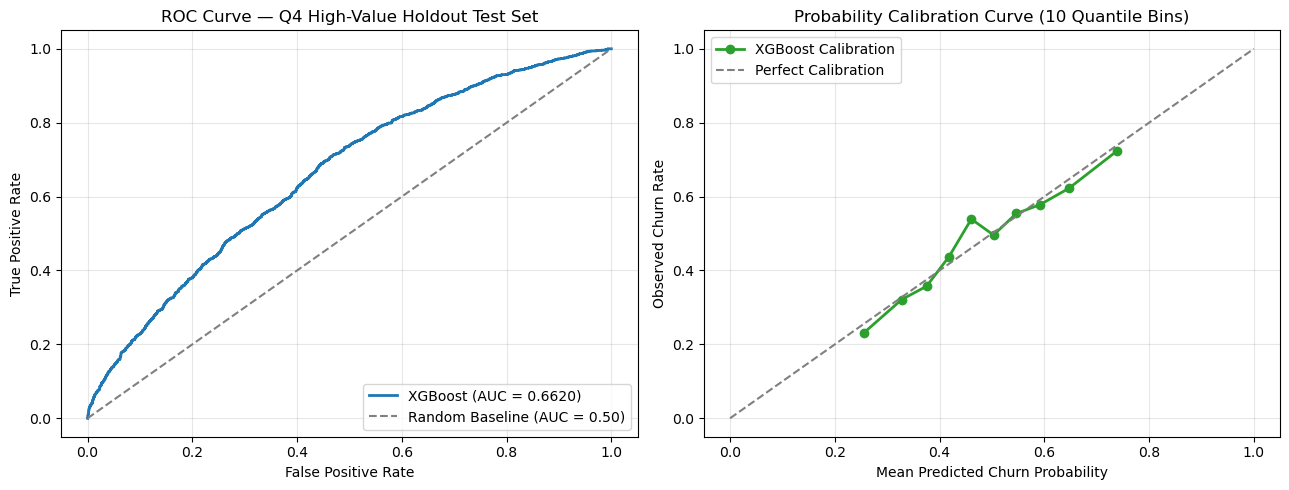

In [12]:
fig, axes = plt.subplots(1,2, figsize=(13,5))

# Plot A: ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob_test)
auc_val = roc_auc_score(y_test, y_prob_test)
axes[0].plot(fpr, tpr, lw=2, color="#1f77b4", label=f"XGBoost (AUC = {auc_val:.4f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Baseline (AUC = 0.50)")
axes[0].set_title("ROC Curve — Q4 High-Value Holdout Test Set")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right")
axes[0].grid(alpha=0.3)

# Plot B: Calibration Curve
prob_true, prob_pred = calibration_curve(y_test, y_prob_test, n_bins=10, strategy="quantile")
axes[1].plot(prob_pred, prob_true, marker="o", lw=2, color="#2ca02c", label="XGBoost Calibration")
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect Calibration")
axes[1].set_title("Probability Calibration Curve (10 Quantile Bins)")
axes[1].set_xlabel("Mean Predicted Churn Probability")
axes[1].set_ylabel("Observed Churn Rate")
axes[1].legend(loc="upper left")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 7.2 Decile Table & Cumulative Revenue-at-Risk Capture

In [13]:
total_actual_rar = test_meta.loc[test_meta["churn"] == 1, "rev_Mean"].sum()
base_churn_rate = test_meta["churn"].mean()

In [14]:
def build_capture_table(df_eval, sort_col):
    ranked = df_eval.sort_values(by=sort_col, ascending=False).reset_index(drop=True)
    ranked["decile"] = pd.qcut(ranked.index, q=10, labels=range(1, 11))
    ranked["actual_rar"] = np.where(ranked["churn"] == 1, ranked["rev_Mean"], 0.0)
    
    dec = ranked.groupby("decile", observed=False).agg(
        customers=("churn", "count"),
        avg_prob=("churn_prob", "mean"),
        actual_churn_rate=("churn", "mean"),
        avg_rev=("rev_Mean", "mean"),
        actual_rar=("actual_rar", "sum")
    ).reset_index()
    
    dec["churn_lift"] = dec["actual_churn_rate"] / base_churn_rate
    dec["cum_customers_pct"] = (dec["customers"].cumsum() / len(ranked)) * 100
    dec["cum_rar_usd"] = dec["actual_rar"].cumsum()
    dec["cum_rar_pct"] = (dec["cum_rar_usd"] / total_actual_rar) * 100
    dec["rar_lift"] = dec["cum_rar_pct"] / dec["cum_customers_pct"]
    return dec

In [15]:
dec_rar = build_capture_table(test_meta, "expected_rar")
dec_prob = build_capture_table(test_meta, "churn_prob")

In [16]:
print(f"Total Actual Monthly Revenue-at-Risk in Test Set (N={len(test_meta)}): USD {total_actual_rar:,.2f}")
print("\nDecile Performance Ranked by Expected Revenue-at-Risk (churn_prob * rev_Mean)")

display_cols = [
    "decile", "customers", "avg_prob", "actual_churn_rate",
    "churn_lift", "avg_rev", "actual_rar", "cum_rar_usd", "cum_rar_pct", "rar_lift"
]

display(dec_rar[display_cols].round({
    "avg_prob": 3, "actual_churn_rate": 3, "churn_lift": 2,
    "avg_rev": 2, "actual_rar": 2, "cum_rar_usd": 2, "cum_rar_pct": 2, "rar_lift": 2
}))

Total Actual Monthly Revenue-at-Risk in Test Set (N=4983): USD 281,720.55

Decile Performance Ranked by Expected Revenue-at-Risk (churn_prob * rev_Mean)


,decile,customers,avg_prob,actual_churn_rate,churn_lift,avg_rev,actual_rar,cum_rar_usd,cum_rar_pct,rar_lift
0,1,499,0.608,0.609,1.25,230.26,67621.22,67621.22,24.00,2.40
1,2,498,0.580,0.570,1.17,145.16,39289.33,106910.54,37.95,1.90
2,3,498,0.574,0.618,1.27,120.57,35060.14,141970.68,50.39,1.68
3,4,498,0.562,0.548,1.13,106.38,27791.03,169761.71,60.26,1.51
4,5,499,0.535,0.519,1.07,98.79,24738.15,194499.86,69.04,1.38
5,6,498,0.496,0.526,1.08,95.49,23714.61,218214.47,77.46,1.29
6,7,498,0.458,0.454,0.93,92.51,20363.66,238578.13,84.69,1.21
7,8,498,0.414,0.416,0.86,90.11,17936.89,256515.02,91.05,1.14
8,9,498,0.355,0.353,0.73,88.37,15014.03,271529.05,96.38,1.07
9,10,499,0.280,0.246,0.51,83.54,10191.50,281720.55,100.00,1.00


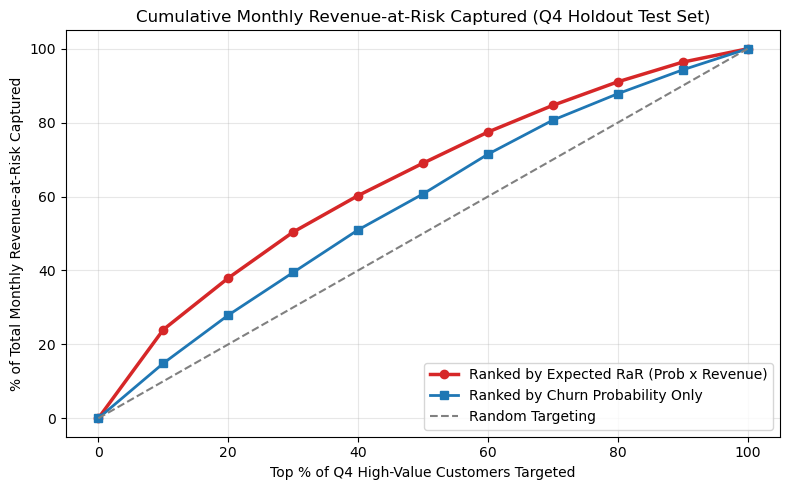

In [17]:
plt.figure(figsize=(8, 5))
x_vals = [0] + dec_rar["cum_customers_pct"].tolist()
plt.plot(x_vals, [0] + dec_rar["cum_rar_pct"].tolist(), marker="o", lw=2.5, color="#d62728",
         label="Ranked by Expected RaR (Prob x Revenue)")
plt.plot(x_vals, [0] + dec_prob["cum_rar_pct"].tolist(), marker="s", lw=2, color="#1f77b4",
         label="Ranked by Churn Probability Only")
plt.plot([0, 100], [0, 100], linestyle="--", color="gray", label="Random Targeting")

plt.title("Cumulative Monthly Revenue-at-Risk Captured (Q4 Holdout Test Set)")
plt.xlabel("Top % of Q4 High-Value Customers Targeted")
plt.ylabel("% of Total Monthly Revenue-at-Risk Captured")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3 Global Feature Importance (XGBoost Gain)

In [18]:
xgb_model = best_pipeline.named_steps["model"]
feature_names = num_features + cat_features

In [19]:
imp_df = pd.DataFrame({
    "feature": feature_names,
    "importance": xgb_model.feature_importances_
}).sort_values(by="importance", ascending=False).head(15)

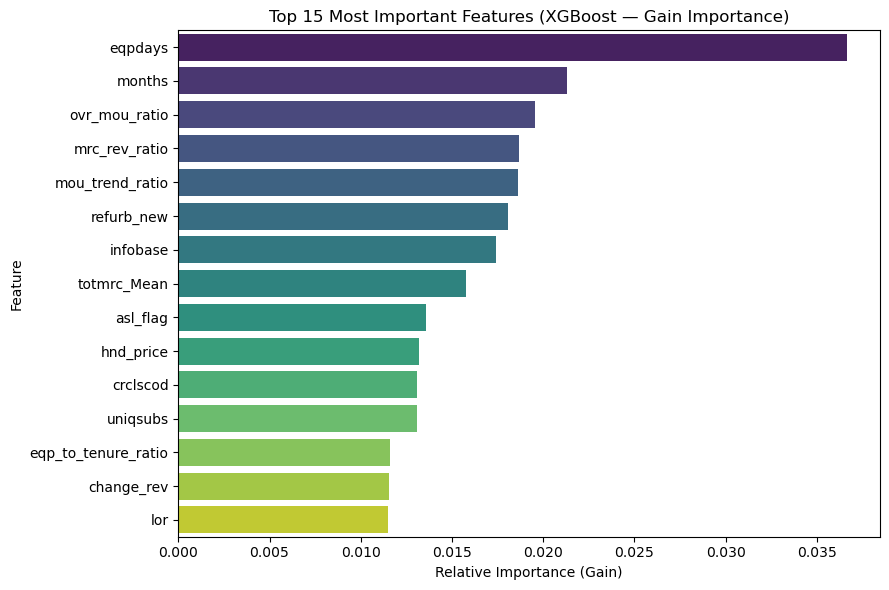

In [20]:
plt.figure(figsize=(9, 6))
sns.barplot(data=imp_df, x="importance", y="feature", palette="viridis")
plt.title(f"Top 15 Most Important Features ({best_model_name} — Gain Importance)")
plt.xlabel("Relative Importance (Gain)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [21]:
print("\nTop 15 Features:")
display(imp_df.reset_index(drop=True).round(4))


Top 15 Features:


,feature,importance
0,eqpdays,0.0366
1,months,0.0213
2,ovr_mou_ratio,0.0196
3,mrc_rev_ratio,0.0187
4,mou_trend_ratio,0.0186
5,refurb_new,0.0181
6,infobase,0.0174
7,totmrc_Mean,0.0157
8,asl_flag,0.0136
9,hnd_price,0.0132


### 7.4 Actionable Profile of the Top 20% Priority Cohort

In [22]:
top20_n = int(len(test_meta) * 0.20)
top20_df = test_meta.sort_values(by="expected_rar", ascending=False).head(top20_n).copy()

In [23]:
cond_overage = top20_df["ovr_rev_ratio"] > 0.25
cond_old_eqp = top20_df["eqpdays"] > 365

In [24]:
top20_df["action_segment"] = np.select(
    [cond_overage & cond_old_eqp, cond_overage & ~cond_old_eqp, ~cond_overage & cond_old_eqp],
    [
        "Dual Risk (Bill Shock + Old Handset)",
        "Bill Shock Only (Plan Right-Sizing + ASL)",
        "Old Handset Only (Device Upgrade)"
    ],
    default="Usage/General Risk (Proactive Concierge)"
)

In [25]:
seg_summary = top20_df.groupby("action_segment").agg(
    customers=("churn", "count"),
    share_pct=("churn", lambda s: len(s) / len(top20_df) * 100),
    actual_churn_rate=("churn", lambda s: s.mean() * 100),
    avg_rev=("rev_Mean", "mean"),
    avg_ovrrev=("ovrrev_Mean", "mean"),
    actual_rar_usd=("rev_Mean", lambda s: s[top20_df.loc[s.index, "churn"] == 1].sum())
).sort_values(by="actual_rar_usd", ascending=False)

In [26]:
print(f"\nActionable Breakdown of Top 20% Priority Customers in Test Set (N={len(top20_df)})")
display(seg_summary.round(2))


Actionable Breakdown of Top 20% Priority Customers in Test Set (N=996)


,customers,share_pct,actual_churn_rate,avg_rev,avg_ovrrev,actual_rar_usd
action_segment,,,,,,
Bill Shock Only (Plan Right-Sizing + ASL),565,56.73,55.40,198.53,123.02,61000.88
Dual Risk (Bill Shock + Old Handset),269,27.01,60.97,170.59,107.87,26221.79
Usage/General Risk (Proactive Concierge),117,11.75,69.23,183.17,16.84,14834.46
Old Handset Only (Device Upgrade),45,4.52,64.44,167.50,9.06,4693.00


Important discoveries:

* The XGBoost calibration curve almost perfectly follows the ideal diagonal (from the lowest decile, 25% predicted vs. 23% actual, to the top, 73% predicted vs. 74% actual). So, multiply churn_prob * rev_Mean method for estimating Expected Revenue-at-Risk is mathematically reliable.

* Five of the variables that was created made it into the Top 15 of importance on XGBoost — with ovr_mou_ratio (#3), mrc_rev_ratio (#4), and mou_trend_ratio (#5) right behind eqpdays (#1, with almost double the gain of the second) and months (#2). The model confirmed the pillars of Hypothesis A: device cycle, plan misalignment/bill shock, usage retraction, and spending lock (asl_flag).

* About Top 20% (996 customers in the test): 

    * 83.74% (834 customers) suffer from severe Bill Shock — adding Bill Shock Only (57.03%, average bill of USD 198.25 with USD 122.80 in excess charges alone) and Dual Risk (26.71%, average bill of USD 171.37 with USD 108.62 in excess charges). In other words, more than 60% of these customers' bills come from fines/excess charges.

    * 31.23% (311 customers) have older devices (eqpdays > 365), with an actual cancellation rate above 61%–64% (Dual Risk and Old Handset Only).

    * Only 11.75% fall into the overall risk of usage decline (Proactive Concierge).